# Project 01: House Price Prediction System
**Machine Learning & AI BootCamp Portfolio Milestone**  
*Instructor: Fahd*

---

## 🏠 Project Overview & Business Case
Real estate valuation has traditionally relied on manual appraisals, which are slow, subjective, and prone to human bias. In this capstone project, you will build an automated, data-driven **House Price Prediction System** capable of accurately estimating property values based on architectural dimensions, location, build quality, and property amenities.

### Objectives:
1. Conduct thorough Exploratory Data Analysis (EDA) on residential sales records (`house_price_prediction_data.csv`).
2. Engineer high-impact domain features (age, luxury indicators, space ratios).
3. Construct a production-grade Scikit-Learn preprocessing pipeline preventing data leakage.
4. Train and benchmark multiple regression architectures:
   - Baseline Mean Model (`DummyRegressor`)
   - Ordinary Least Squares Multiple Linear Regression
   - Polynomial Feature Regression
   - Regularized Regression (Ridge & Lasso)
5. Perform hyperparameter tuning to find optimal regularization strength $\alpha$.
6. Evaluate model performance using MAE, RMSE, and $R^2$, and extract top market value drivers.


---
## Student Information
- **Student Name:*[Md.Fahimur Rahman Khan Fahim]*
- **Batch:** *[MLB-02]*
- **Date:** *[Enter submission date]*


In [13]:
# Run this cell first to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Project libraries successfully imported!")


Project libraries successfully imported!


---
## Step 1: Data Ingestion & Initial Inspection
1. Load `house_price_prediction_data.csv` into a DataFrame named `df`.
2. Inspect the first 5 rows and verify the shape and data types.
3. Check for missing values across all columns.


In [4]:
# TODO 1.1: Load dataset and inspect first 5 rows
# df = pd.read_csv(...)
import pandas as pd
df=pd.read_csv('E:\\AIML bootCamp\\Capastone Project\\house_price_prediction_data - house_price_prediction_data.csv') 
print(df.head())


  property_id  sqft_living  bedrooms  bathrooms  lot_size_sqft  floors  \
0   PROP-2001         1180         3       1.00           5650     1.0   
1   PROP-2002         2570         3       2.25           7242     2.0   
2   PROP-2003          770         2       1.00          10000     1.0   
3   PROP-2004         1960         4       3.00           5000     1.0   
4   PROP-2005         1680         3       2.00           8080     1.0   

   waterfront  view_score  condition_rating  grade_score  yr_built  \
0           0           0                 3            7      1955   
1           0           0                 3            7      1951   
2           0           0                 3            6      1933   
3           0           0                 5            7      1965   
4           0           0                 3            8      1987   

  neighborhood  price_usd  
0      Suburbs     321950  
1    Northside     538000  
2     Downtown     280000  
3      WestEnd     604

In [5]:
import pandas as pd
df.shape


(2500, 13)

In [ ]:
df.dtypes

property_id             str
sqft_living           int64
bedrooms              int64
bathrooms           float64
lot_size_sqft         int64
floors              float64
waterfront            int64
view_score            int64
condition_rating      int64
grade_score           int64
yr_built              int64
neighborhood            str
price_usd             int64
dtype: object

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   property_id       2500 non-null   str    
 1   sqft_living       2500 non-null   int64  
 2   bedrooms          2500 non-null   int64  
 3   bathrooms         2500 non-null   float64
 4   lot_size_sqft     2500 non-null   int64  
 5   floors            2500 non-null   float64
 6   waterfront        2500 non-null   int64  
 7   view_score        2500 non-null   int64  
 8   condition_rating  2500 non-null   int64  
 9   grade_score       2500 non-null   int64  
 10  yr_built          2500 non-null   int64  
 11  neighborhood      2500 non-null   str    
 12  price_usd         2500 non-null   int64  
dtypes: float64(2), int64(9), str(2)
memory usage: 295.0 KB


In [6]:
df.isnull()

,property_id,sqft_living,bedrooms,bathrooms,lot_size_sqft,floors,waterfront,view_score,condition_rating,grade_score,yr_built,neighborhood,price_usd
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,False,False,False,False,False,False,False,False,False,False,False,False,False
2496,False,False,False,False,False,False,False,False,False,False,False,False,False
2497,False,False,False,False,False,False,False,False,False,False,False,False,False
2498,False,False,False,False,False,False,False,False,False,False,False,False,False


In [7]:
df.isnull().sum()

property_id         0
sqft_living         0
bedrooms            0
bathrooms           0
lot_size_sqft       0
floors              0
waterfront          0
view_score          0
condition_rating    0
grade_score         0
yr_built            0
neighborhood        0
price_usd           0
dtype: int64

---
## Step 2: Exploratory Data Analysis (EDA)
1. Examine the summary statistics of `price_usd`.
2. Plot a histogram with KDE of `price_usd` to observe distribution shape and skewness.
3. Plot a boxplot comparing prices across different `neighborhood` categories.


In [ ]:
# TODO 2.1: Price distribution plot & summary statistics

# TODO 2.2: Price vs. Neighborhood boxplot


In [14]:
df['price_usd'].describe()

count    2.500000e+03
mean     5.893224e+05
std      2.723450e+05
min      2.500000e+05
25%      4.090000e+05
50%      5.020000e+05
75%      6.440000e+05
max      1.579500e+06
Name: price_usd, dtype: float64

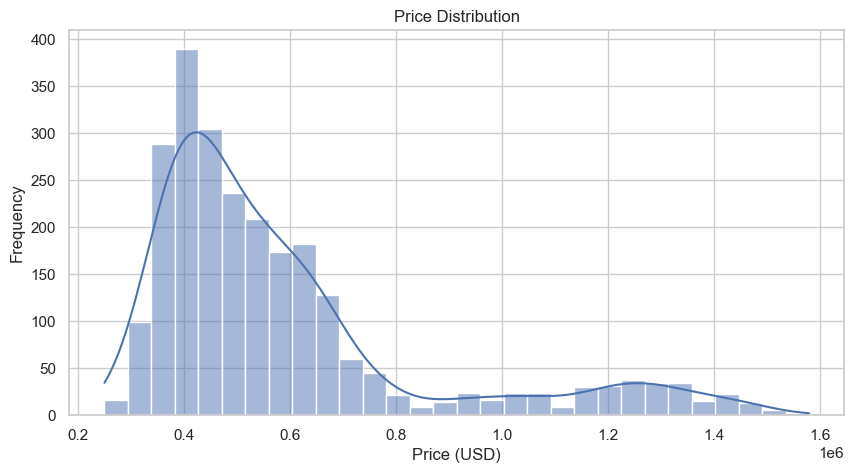

In [15]:
plt.figure(figsize=(10,5))
sns.histplot(data=df,
             x='price_usd',
             kde=True,
             bins=30
             )
plt.title('Price Distribution')
plt.xlabel('Price (USD)')
plt.ylabel('Frequency')
plt.show()

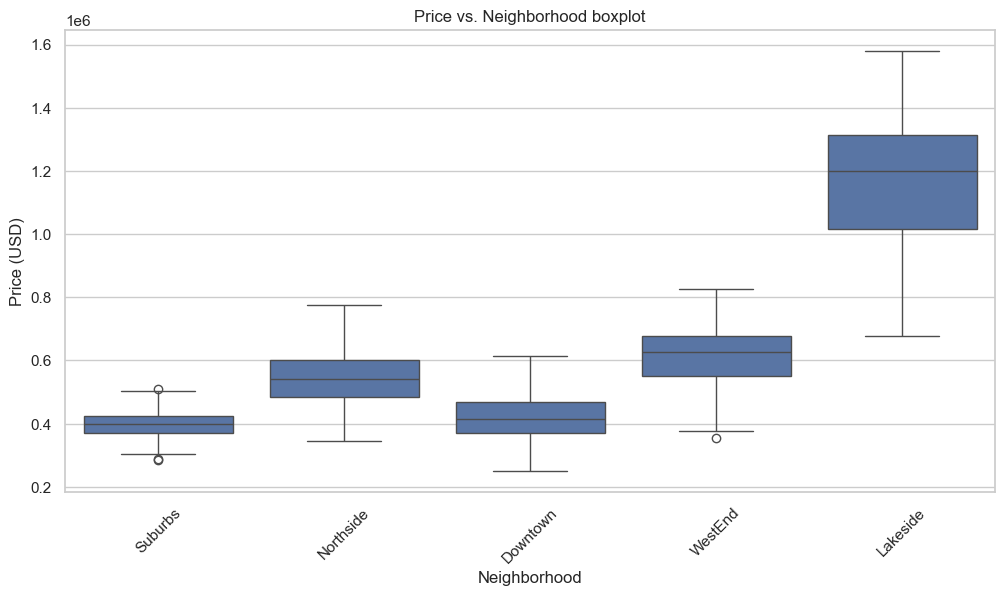

In [16]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df,
             x='neighborhood',y='price_usd')
plt.title('Price vs. Neighborhood boxplot')
plt.xlabel('Neighborhood')
plt.ylabel('Price (USD)')
plt.xticks(rotation=45)

plt.show()  

---
## Step 3: Domain Feature Engineering
In real estate analytics, raw features alone do not tell the whole story.
1. Create `property_age`: Number of years since construction relative to `2024` ($2024 - \text{yr\_built}$).
2. Create `bath_to_bed_ratio`: Ratio of bathrooms to bedrooms ($\frac{\text{bathrooms}}{\text{bedrooms}}$).
3. Create a binary indicator `is_luxury`: $1$ if `waterfront == 1` OR `grade_score >= 10`, else $0$.
4. Display the first 5 rows of these newly created features.


In [ ]:
# TODO 3.1: Create property_age, bath_to_bed_ratio, and is_luxury



# TODO 3.2: Display first 5 rows of engineered features


In [99]:
print(df.columns.tolist())

['property_id', 'sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront', 'view_score', 'condition_rating', 'grade_score', 'yr_built', 'neighborhood', 'price_usd', 'property age', 'bath_to_bed_ratio', 'is_luxury', 'property_age']


In [100]:
df.head(10)

,property_id,sqft_living,bedrooms,bathrooms,lot_size_sqft,floors,waterfront,view_score,condition_rating,grade_score,yr_built,neighborhood,price_usd,property age,bath_to_bed_ratio,is_luxury,property_age
0,PROP-2001,1180,3,1.00,5650,1.0,0,0,3,7,1955,Suburbs,321950,69,0.333333,0,69
1,PROP-2002,2570,3,2.25,7242,2.0,0,0,3,7,1951,Northside,538000,73,0.750000,0,73
2,PROP-2003,770,2,1.00,10000,1.0,0,0,3,6,1933,Downtown,280000,91,0.500000,0,91
3,PROP-2004,1960,4,3.00,5000,1.0,0,0,5,7,1965,WestEnd,604000,59,0.750000,0,59
4,PROP-2005,1680,3,2.00,8080,1.0,0,0,3,8,1987,Suburbs,510000,37,0.666667,0,37
5,PROP-2006,5420,4,4.50,101930,1.0,0,0,3,11,2001,Lakeside,1225000,23,1.125000,1,23
6,PROP-2007,1715,3,2.25,6819,2.0,0,0,3,7,1995,Northside,457500,29,0.750000,0,29
7,PROP-2008,1060,3,1.50,9711,1.0,0,0,3,7,1963,Downtown,391000,61,0.500000,0,61
8,PROP-2009,1780,3,1.00,7470,1.0,0,0,3,7,1960,Suburbs,395000,64,0.333333,0,64
9,PROP-2010,1890,3,2.50,6560,2.0,0,0,3,7,2003,WestEnd,423000,21,0.833333,0,21


In [102]:
df['property_age']=2024-df['yr_built']
df[['yr_built', 'property_age']].head(10)

,yr_built,property_age
0,1955,69
1,1951,73
2,1933,91
3,1965,59
4,1987,37
5,2001,23
6,1995,29
7,1963,61
8,1960,64
9,2003,21


In [81]:
df['bath_to_bed_ratio'] = df['bathrooms'] / df['bedrooms']
df[['bathrooms', 'bedrooms', 'bath_to_bed_ratio']].head()

,bathrooms,bedrooms,bath_to_bed_ratio
0,1.00,3,0.333333
1,2.25,3,0.750000
2,1.00,2,0.500000
3,3.00,4,0.750000
4,2.00,3,0.666667


In [82]:
df['is_luxury'] = (
    (df['waterfront'] == 1) |
    (df['grade_score'] >= 10)
).astype(int)
df[['waterfront', 'grade_score', 'is_luxury']].head()


,waterfront,grade_score,is_luxury
0,0,7,0
1,0,7,0
2,0,6,0
3,0,7,0
4,0,8,0


In [103]:
df[['property_age', 'bath_to_bed_ratio', 'is_luxury']].head()

,property_age,bath_to_bed_ratio,is_luxury
0,69,0.333333,0
1,73,0.750000,0
2,91,0.500000,0
3,59,0.750000,0
4,37,0.666667,0


---
## Step 4: Preprocessing Pipeline Construction
1. Define feature matrix `X` and target `y` (`price_usd`). Drop `property_id` and `price_usd` from `X`.
2. Identify numerical columns and categorical columns:
   - Numerical: `['sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront', 'view_score', 'condition_rating', 'grade_score', 'property_age', 'bath_to_bed_ratio', 'is_luxury']`
   - Categorical: `['neighborhood']`
3. Build a `ColumnTransformer` named `preprocessor`:
   - Standardize numerical features with `StandardScaler()`.
   - One-hot encode `neighborhood` with `OneHotEncoder(drop='first', sparse_output=False)`.
4. Perform an **80/20 train-test split** using `train_test_split(X, y, test_size=0.20, random_state=42)`.


In [ ]:
# TODO 4.1: Define X and y

# TODO 4.2: Build ColumnTransformer preprocessor

# TODO 4.3: Perform 80/20 train-test split


In [104]:
X = df.drop(['property_id', 'price_usd'], axis=1)
y = df['price_usd']


numerical_cols = [
    'sqft_living',
    'bedrooms',
    'bathrooms',
    'lot_size_sqft',
    'floors',
    'waterfront',
    'view_score',
    'condition_rating',
    'grade_score',
    'property_age',
    'bath_to_bed_ratio',
    'is_luxury'
]

categorical_cols = ['neighborhood']


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2000, 15)
X_test shape: (500, 15)
y_train shape: (2000,)
y_test shape: (500,)


In [105]:
X = df.drop(['property_id', 'price_usd'], axis=1)
y = df['price_usd']

In [106]:
X.columns.tolist()

['sqft_living',
 'bedrooms',
 'bathrooms',
 'lot_size_sqft',
 'floors',
 'waterfront',
 'view_score',
 'condition_rating',
 'grade_score',
 'yr_built',
 'neighborhood',
 'property age',
 'bath_to_bed_ratio',
 'is_luxury',
 'property_age']

In [107]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(X_train.shape)
print(X_test.shape)

(2000, 15)
(500, 15)


In [108]:
print('property_age:', 'property_age' in X_train.columns)
print('bath_to_bed_ratio:', 'bath_to_bed_ratio' in X_train.columns)
print('is_luxury:', 'is_luxury' in X_train.columns)

property_age: True
bath_to_bed_ratio: True
is_luxury: True


In [96]:
print('property_age' in df.columns)
print(df.columns.tolist())

False
['property_id', 'sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront', 'view_score', 'condition_rating', 'grade_score', 'yr_built', 'neighborhood', 'price_usd', 'property age', 'bath_to_bed_ratio', 'is_luxury']


---
## Step 5: Model Training & Experimentation
Train 4 distinct regression architectures inside clean Scikit-Learn pipelines:
1. **Model 1: Baseline Dummy Regressor** (`DummyRegressor(strategy='mean')`)
2. **Model 2: OLS Linear Regression** (`LinearRegression()`)
3. **Model 3: Ridge Regression** (`Ridge(alpha=10.0)`)
4. **Model 4: Lasso Regression** (`Lasso(alpha=100.0)`)


In [ ]:
# TODO 5.1: Build and fit Pipeline for Model 1 (Dummy Baseline)

# TODO 5.2: Build and fit Pipeline for Model 2 (Linear Regression)

# TODO 5.3: Build and fit Pipeline for Model 3 (Ridge Regression)

# TODO 5.4: Build and fit Pipeline for Model 4 (Lasso Regression)


In [94]:
from sklearn.base import clone
dummy_Pipeline = Pipeline([('preprocessor',clone(preprocessor)),('model',DummyRegressor(strategy='mean'))])


In [109]:
dummy_Pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['sqft_living','bedrooms','bathrooms',...,'bath_to_bed_ratio','is_luxury', 'property_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

In [110]:
dummy_pred = dummy_Pipeline.predict(X_test)
print(dummy_pred[:5])

[587526.975 587526.975 587526.975 587526.975 587526.975]


In [111]:
from sklearn.base import clone
linear_Pipeline = Pipeline([('preprocessor',clone(preprocessor)),('model', LinearRegression())])

In [112]:
linear_Pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['sqft_living','bedrooms','bathrooms',...,'bath_to_bed_ratio','is_luxury', 'property_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

In [113]:
linear_pred = linear_Pipeline.predict(X_test)
print(linear_pred[:5])

[ 633989.2546455   411729.23950611  356033.99209736 1278483.70863559
  399857.11959649]


In [114]:
from sklearn.base import clone
ridge_Pipeline = Pipeline([('preprocessor',clone(preprocessor)),('model',Ridge(alpha=1.0))])


In [115]:
ridge_Pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['sqft_living','bedrooms','bathrooms',...,'bath_to_bed_ratio','is_luxury', 'property_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

In [116]:
ridge_pred = ridge_Pipeline.predict(X_test)
print(ridge_pred[:5])

[ 633690.96210338  411705.75544467  355993.03573564 1278510.61696956
  400303.48727317]


In [117]:
lasso_Pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', Lasso(alpha=100.0))
])

In [118]:
lasso_Pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['sqft_living','bedrooms','bathrooms',...,'bath_to_bed_ratio','is_luxury', 'property_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

In [76]:
lasso_pred = lasso_Pipeline.predict(X_test)
print(lasso_pred[:5])

[ 632705.08861466  411988.44355105  356564.66466308 1278126.86248317
  400876.18924042]


---
## Step 6: Model Evaluation & Comparative Benchmark
1. For each model, generate predictions on the holdout test set (`X_test`).
2. Calculate **MAE**, **RMSE**, and **$R^2$ Score** on the test set.
3. Consolidate results into a clean comparative DataFrame named `benchmark_df` and display it.


In [119]:
# TODO 6.1: Compute test metrics for all 4 models and build benchmark_df


In [ ]:
dummy_pred = dummy_Pipeline.predict(X_test)
linear_pred = linear_Pipeline.predict(X_test)
ridge_pred = ridge_Pipeline.predict(X_test)
lasso_pred = lasso_Pipeline.predict(X_test)

models = {
    'Dummy Regressor': dummy_pred,
    'Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred
}

results = []

for model_name, y_pred in models.items():

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    })

benchmark_df = pd.DataFrame(results)
print("Model Performance Benchmark:")
display(benchmark_df.round(2))


Model Performance Benchmark:


,Model,MAE,MSE,RMSE,R2
0,Dummy Regressor,197459.06,7.833833e+10,279889.86,-0.00
1,Linear Regression,21912.16,7.692015e+08,27734.48,0.99
2,Ridge Regression,21904.56,7.695485e+08,27740.74,0.99
3,Lasso Regression,21991.87,7.758341e+08,27853.80,0.99


---
## Step 7: Hyperparameter Tuning for Regularization
Use `GridSearchCV` on the Ridge pipeline to find the optimal regularization strength $\alpha$ from:
`param_grid = {'regressor__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]}`.
1. Run 5-fold cross-validation optimizing for negative root mean squared error (`scoring='neg_root_mean_squared_error'`).
2. Print the best alpha value and the best cross-validation score.


In [ ]:
# TODO 7.1: Setup and run GridSearchCV on Ridge pipeline

# TODO 7.2: Print best alpha and best score


In [126]:
param_grid = {
    'model__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]
}

ridge_grid = GridSearchCV(
    estimator=ridge_Pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Alpha:", ridge_grid.best_params_['model__alpha'])
print("Best CV Score:", ridge_grid.best_score_)

Best Alpha: 0.1
Best CV Score: -29357.272874010603


---
## Step 8: Residual Analysis & Business Insights
1. Generate residuals ($y_{\text{test}} - \hat{y}_{\text{pred}}$) for your best tuned model.
2. Plot Actual vs. Predicted prices and the Residual plot.
3. Extract and plot the top 5 most influential positive and negative coefficients driving home valuation.


In [ ]:
# TODO 8.1: Plot Actual vs Predicted & Residuals for best model

# TODO 8.2: Plot Top Feature Coefficients


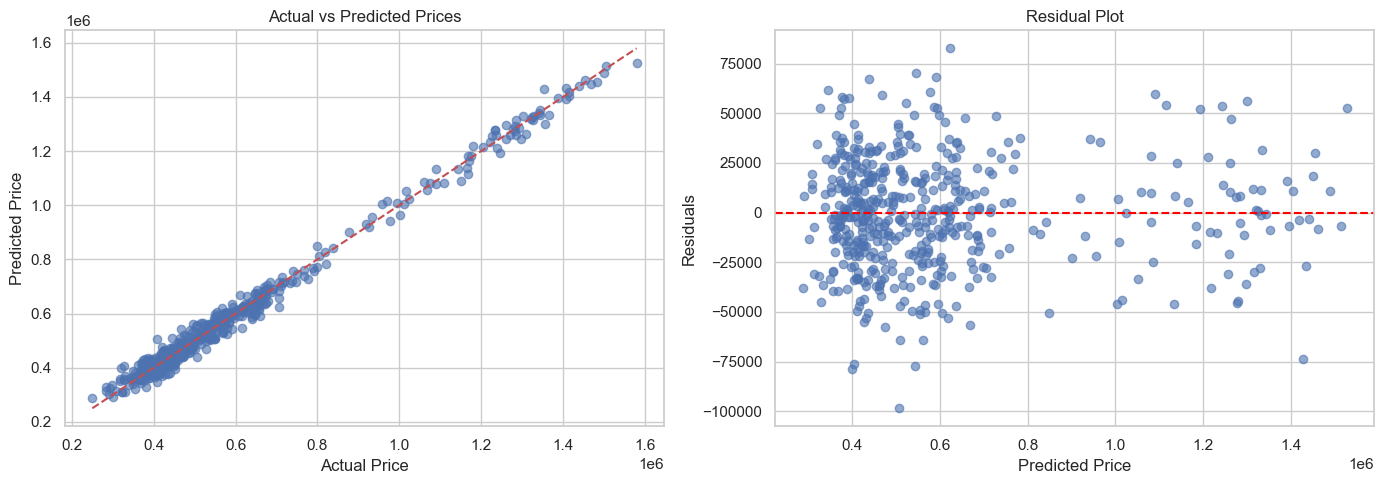

In [ ]:

best_ridge_model = ridge_grid.best_estimator_

best_pred = best_ridge_model.predict(X_test)

residuals = y_test - best_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, best_pred, alpha=0.6)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Actual vs Predicted Prices")

axes[1].scatter(best_pred, residuals, alpha=0.6)
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

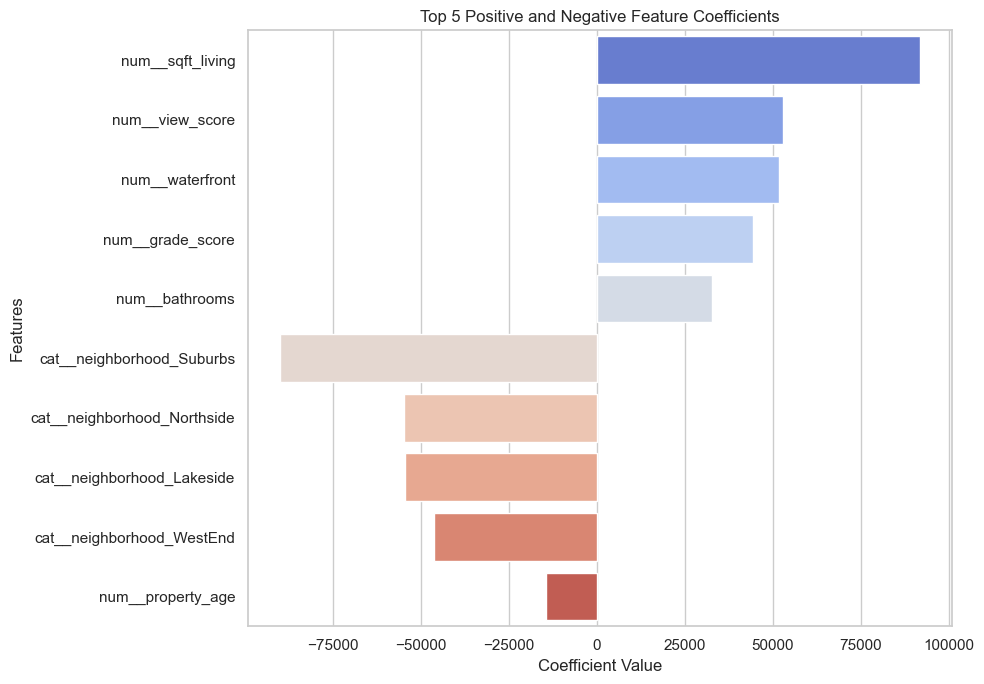

In [128]:
ridge_model = best_ridge_model.named_steps['model']

feature_names = best_ridge_model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = ridge_model.coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

top_positive = coef_df.nlargest(5, 'Coefficient')
top_negative = coef_df.nsmallest(5, 'Coefficient')

top_features = pd.concat([top_positive, top_negative])

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Coefficient',
    y='Feature',
    hue='Feature',
    palette='coolwarm',
    legend=False
)

plt.title("Top 5 Positive and Negative Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

---
### 🏆 Capstone Project Completed!
You have engineered an end-to-end Machine Learning valuation system:
- Built a leak-free preprocessing pipeline handling mixed data types.
- Compared baseline, linear, and regularized models.
- Tuned hyperparameters using cross-validation.
- Uncovered key business drivers of residential real estate valuation!
